# MoodSense AI: Text-Based Human Mood Detection
## Model Training, Comparative Evaluation, and Deployment Artifact

This notebook documents the reproducible machine-learning workflow used by the
local MoodSense AI web application. The task is a seven-class text
classification problem: **happy, calm, excited, anxious, sad, angry, and
neutral**.

> **Responsible-use boundary:** The supplied dataset is synthetic and curated
> for software demonstration and academic documentation. The model is a mood
> reflection tool—not a clinical diagnostic instrument. Its results must not be
> presented as evidence of clinical validity.

### 1. Reproducibility setup

A fixed random state is used for dataset splitting, model training, and
cross-validation. The same TF–IDF configuration is used for every candidate so
the comparison reflects classifier differences rather than different feature
representations.

In [1]:
from pathlib import Path
import json, platform, warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_recall_fscore_support, roc_auc_score, roc_curve, auc
)
from sklearn.model_selection import (
    StratifiedKFold, cross_val_score, train_test_split
)
from sklearn.preprocessing import label_binarize

from generate_dataset import write_dataset
from train_model import RANDOM_STATE, candidate_models, metric_row

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_colwidth', 110)

ROOT = Path.cwd()
DATA_PATH = ROOT / 'data' / 'mood_text_dataset.csv'
MODEL_PATH = ROOT / 'models' / 'mood_pipeline.joblib'
METADATA_PATH = ROOT / 'models' / 'model_metadata.json'

print('Python:', platform.python_version())
print('scikit-learn:', sklearn.__version__)
print('Project root:', ROOT)

Python: 3.12.13
scikit-learn: 1.8.0
Project root: /workspace/scratch/cb04da410e0b/moodsense_local


### 2. Dataset creation and inspection

The generator builds a balanced corpus from curated mood-specific language
patterns, neutral situations, contextual phrases, and controlled surface-form
variations. The `source` field makes the synthetic provenance explicit.

In [2]:
if not DATA_PATH.exists():
    write_dataset(DATA_PATH, per_class=280, seed=RANDOM_STATE)

df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate texts:', int(df.duplicated(subset=['text']).sum()))
display(df.sample(7, random_state=RANDOM_STATE).sort_values('mood'))

Dataset shape: 1,960 rows × 3 columns
Missing values: 0
Duplicate texts: 0
                                                                                                                                          text     mood                source
450                    Lately, I have had enough of these excuses after speaking with my family. I am trying to understand the feeling better.    angry  synthetic_curated_v1
1096       At this point, I am overwhelmed by all these deadlines while preparing for the coming week. That is the best way I can describe it.  anxious  synthetic_curated_v1
128        Since this morning, I am comfortable with my decision because of the conversation we had. I have noticed the feeling quite clearly.     calm  synthetic_curated_v1
383              At this point, I feel blessed by the support around me after spending some time alone. It is affecting the way I see the day.    happy  synthetic_curated_v1
1489    After the recent events, my heart feels light a

      Mood  Frequency  Percentage
0    Angry        280       14.29
1  Anxious        280       14.29
2     Calm        280       14.29
3  Excited        280       14.29
4    Happy        280       14.29
5  Neutral        280       14.29
6      Sad        280       14.29


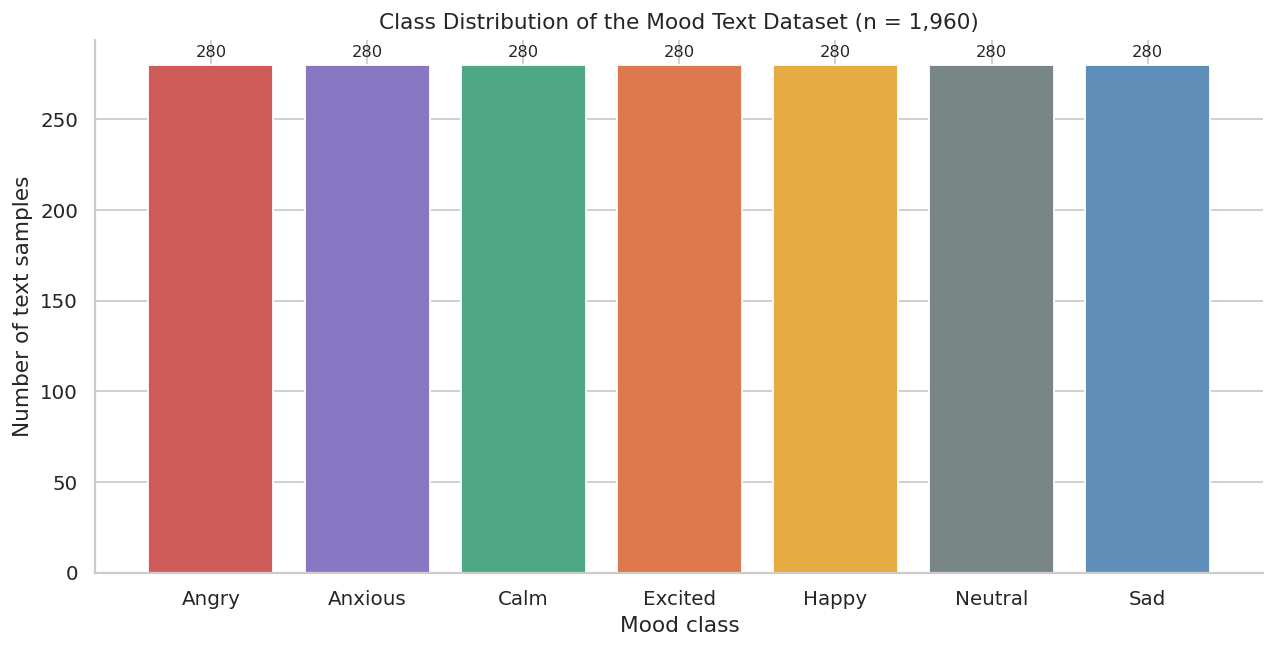

In [3]:
class_counts = df['mood'].value_counts().sort_index()
distribution_table = pd.DataFrame({
    'Mood': class_counts.index.str.title(),
    'Frequency': class_counts.values,
    'Percentage': (class_counts.values / len(df) * 100).round(2)
})
display(distribution_table)

colours = ['#CF5C59','#8878C4','#4DA784','#DE784D','#E7AB43','#788785','#5F8FB8']
fig, ax = plt.subplots(figsize=(10, 5.2))
bars = ax.bar(distribution_table['Mood'], distribution_table['Frequency'], color=colours)
ax.set(title='Class Distribution of the Mood Text Dataset (n = 1,960)',
       xlabel='Mood class', ylabel='Number of text samples')
ax.bar_label(bars, padding=3, fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

**Interpretation.** Each mood contains the same number of observations (280,
14.29%). Consequently, accuracy is not inflated by a majority class and macro
averages are directly interpretable across all seven moods.

### 3. Stratified training and test partitions

An 80:20 hold-out design is used. Stratification preserves the equal class
distribution in both partitions. The test set is not used for fitting.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['mood'], test_size=0.20,
    random_state=RANDOM_STATE, stratify=df['mood']
)

split_summary = pd.DataFrame({
    'Partition': ['Training', 'Testing', 'Total'],
    'Observations': [len(X_train), len(X_test), len(df)],
    'Percentage': [len(X_train)/len(df)*100, len(X_test)/len(df)*100, 100]
})
display(split_summary.style.format({'Percentage': '{:.1f}%'}))
print('Training class counts:', y_train.value_counts().sort_index().to_dict())
print('Testing class counts:', y_test.value_counts().sort_index().to_dict())

  Partition  Observations  Percentage
0  Training          1568        80.0
1   Testing           392        20.0
2     Total          1960       100.0
Training class counts: {'angry': 224, 'anxious': 224, 'calm': 224, 'excited': 224, 'happy': 224, 'neutral': 224, 'sad': 224}
Testing class counts: {'angry': 56, 'anxious': 56, 'calm': 56, 'excited': 56, 'happy': 56, 'neutral': 56, 'sad': 56}


### 4. Candidate model training and comparison

Three probabilistic classifiers are compared:

1. Multinomial Naive Bayes—a standard sparse-text baseline.
2. Logistic Regression—a discriminative linear classifier.
3. SGD with log-loss—a scalable linear probabilistic classifier.

The feature pipeline applies lowercase normalization, Unicode accent handling,
English stop-word removal, unigram and bigram TF–IDF, rare-term filtering, and
sublinear term frequency.

In [5]:
fitted_models = {}
comparison_rows = []

for model_name, model in candidate_models().items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    fitted_models[model_name] = model
    comparison_rows.append(metric_row(model_name, y_test, predictions))

comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values(['macro_f1', 'accuracy'], ascending=False)
    .reset_index(drop=True)
)
display(comparison.style.format({
    'accuracy':'{:.4f}', 'macro_precision':'{:.4f}',
    'macro_recall':'{:.4f}', 'macro_f1':'{:.4f}', 'weighted_f1':'{:.4f}'
}).highlight_max(subset=['accuracy','macro_precision','macro_recall','macro_f1','weighted_f1'], color='#dce8dd'))

selected_name = comparison.iloc[0]['model']
selected_model = fitted_models[selected_name]
y_pred = selected_model.predict(X_test)
y_probability = selected_model.predict_proba(X_test)
print('Selected deployment model:', selected_name)

                     model  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
0      Logistic Regression  1.000000         1.000000      1.000000  1.000000     1.000000
1  SGD Log-Loss Classifier  1.000000         1.000000      1.000000  1.000000     1.000000
2  Multinomial Naive Bayes  0.997449         0.997494      0.997449  0.997449     0.997449
Selected deployment model: Logistic Regression


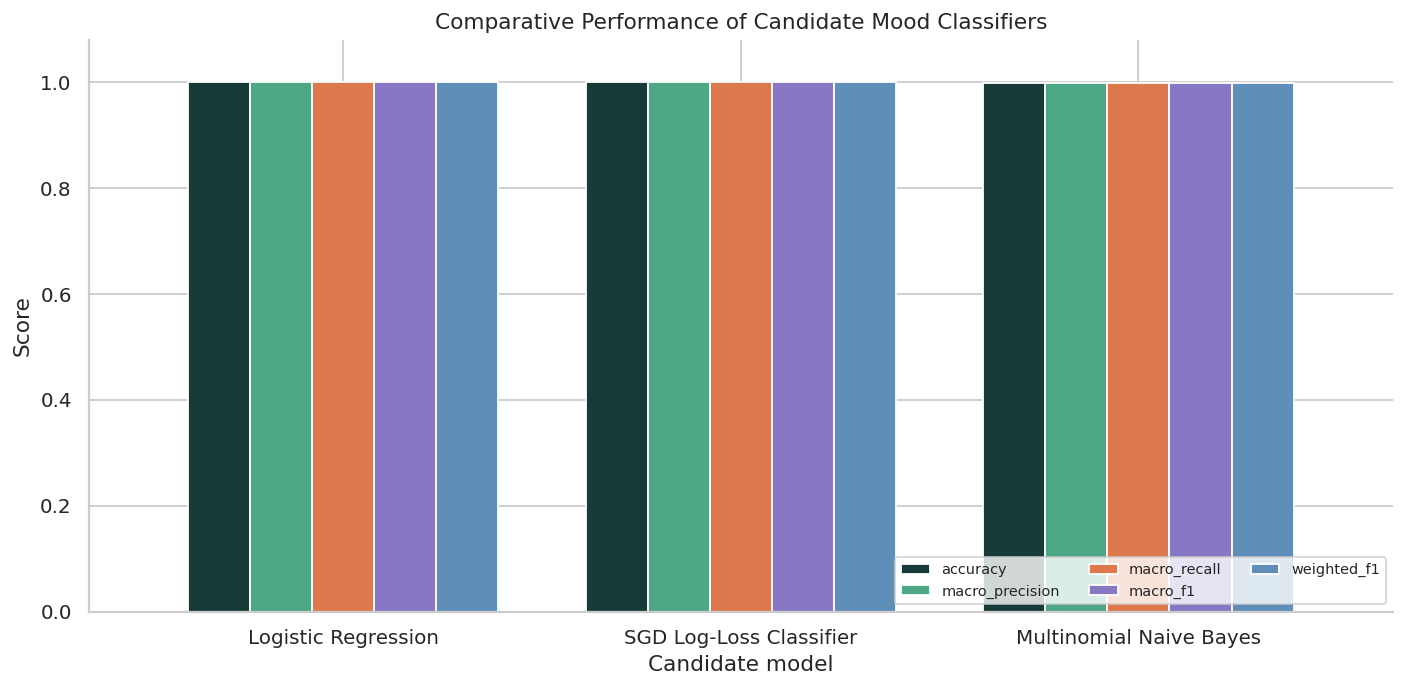

In [6]:
metric_columns = ['accuracy','macro_precision','macro_recall','macro_f1','weighted_f1']
plot_data = comparison.set_index('model')[metric_columns]
ax = plot_data.plot(kind='bar', figsize=(11,5.5), width=.78,
                    color=['#173B39','#4DA784','#DE784D','#8878C4','#5F8FB8'])
ax.set(title='Comparative Performance of Candidate Mood Classifiers',
       xlabel='Candidate model', ylabel='Score', ylim=(0,1.08))
ax.legend(loc='lower right', ncol=3, fontsize=8)
ax.tick_params(axis='x', rotation=0)
sns.despine()
plt.tight_layout()
plt.show()

### 5. Detailed evaluation of the selected model

The classification report provides class-specific precision, recall, and F1.
Macro averages give every class equal weight, while weighted averages account
for class frequency.

In [7]:
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
report_table = pd.DataFrame(report_dict).T
display(report_table.style.format('{:.4f}'))
print(classification_report(y_test, y_pred, zero_division=0))

              precision  recall  f1-score  support
angry               1.0     1.0       1.0     56.0
anxious             1.0     1.0       1.0     56.0
calm                1.0     1.0       1.0     56.0
excited             1.0     1.0       1.0     56.0
happy               1.0     1.0       1.0     56.0
neutral             1.0     1.0       1.0     56.0
sad                 1.0     1.0       1.0     56.0
accuracy            1.0     1.0       1.0      1.0
macro avg           1.0     1.0       1.0    392.0
weighted avg        1.0     1.0       1.0    392.0
              precision    recall  f1-score   support

       angry       1.00      1.00      1.00        56
     anxious       1.00      1.00      1.00        56
        calm       1.00      1.00      1.00        56
     excited       1.00      1.00      1.00        56
       happy       1.00      1.00      1.00        56
     neutral       1.00      1.00      1.00        56
         sad       1.00      1.00      1.00        56

    a

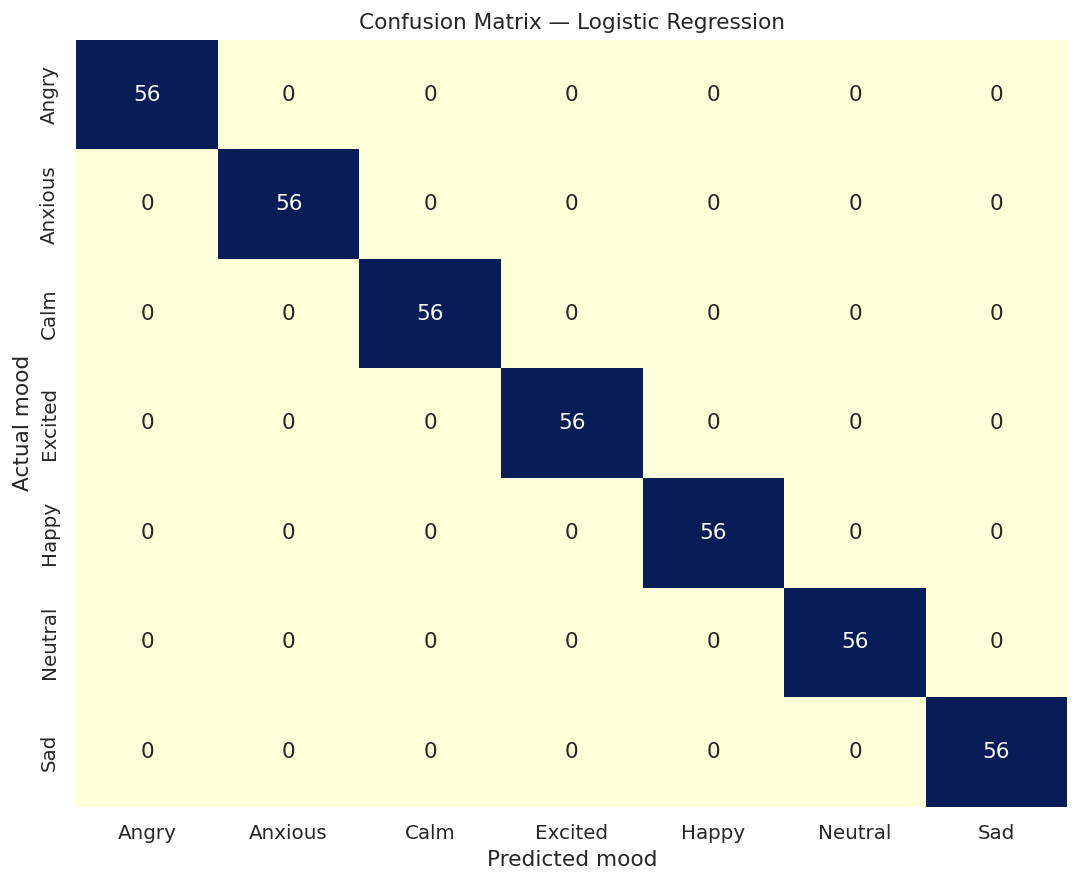

In [8]:
labels = list(selected_model.classes_)
matrix = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(matrix, annot=True, fmt='d', cmap='YlGnBu', cbar=False,
            xticklabels=[x.title() for x in labels],
            yticklabels=[x.title() for x in labels], ax=ax)
ax.set(title=f'Confusion Matrix — {selected_name}',
       xlabel='Predicted mood', ylabel='Actual mood')
plt.tight_layout()
plt.show()

**Confusion-matrix reading.** Values on the main diagonal are correct
classifications. Any off-diagonal value identifies the actual and predicted
mood involved in an error. Because the demonstration language templates are
highly separable, results may be unusually strong and must not be generalized
to unrestricted real-world or clinical text.

Macro one-vs-rest ROC–AUC: 1.0


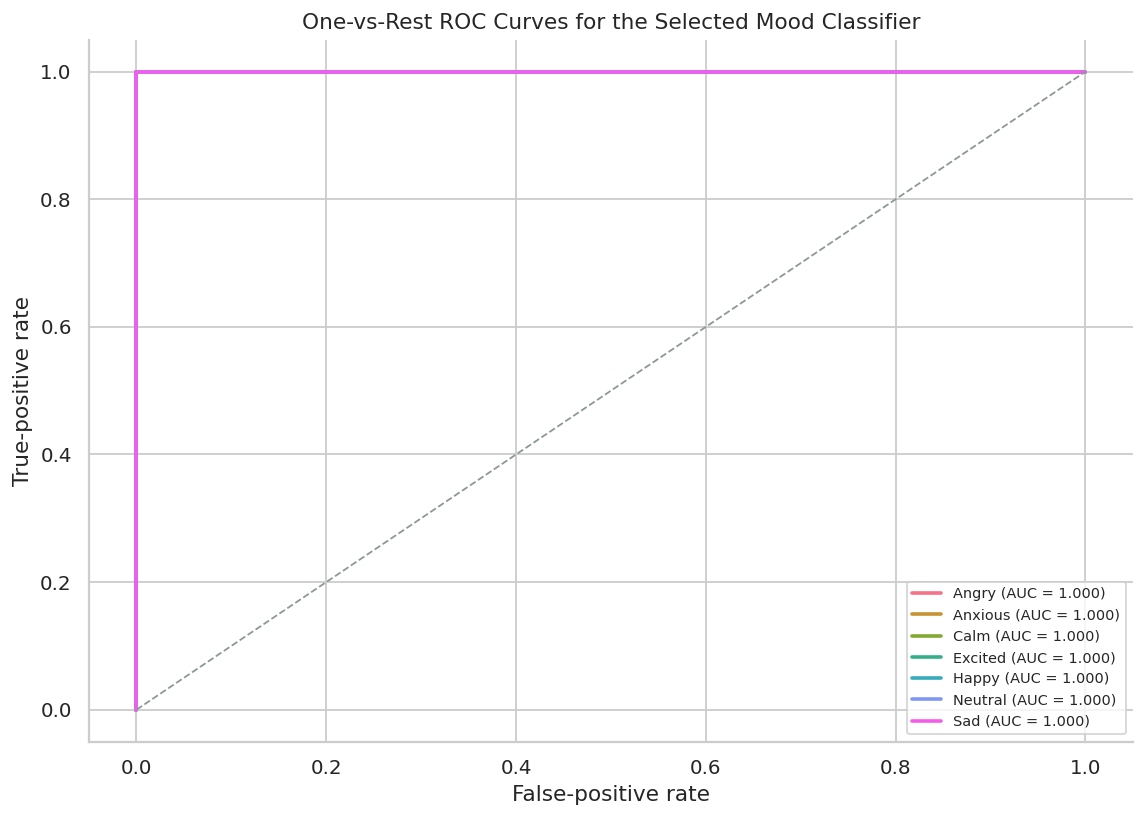

In [9]:
binary_truth = label_binarize(y_test, classes=labels)
fig, ax = plt.subplots(figsize=(9, 6.5))
palette = sns.color_palette('husl', len(labels))
auc_by_class = {}
for index, (label, colour) in enumerate(zip(labels, palette)):
    false_positive, true_positive, _ = roc_curve(binary_truth[:, index], y_probability[:, index])
    class_auc = auc(false_positive, true_positive)
    auc_by_class[label] = class_auc
    ax.plot(false_positive, true_positive, lw=2, color=colour,
            label=f'{label.title()} (AUC = {class_auc:.3f})')
ax.plot([0,1],[0,1],'--',color='#8d9893',lw=1)
ax.set(title='One-vs-Rest ROC Curves for the Selected Mood Classifier',
       xlabel='False-positive rate', ylabel='True-positive rate')
ax.legend(loc='lower right', fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()
print('Macro one-vs-rest ROC–AUC:', round(roc_auc_score(binary_truth, y_probability, average='macro', multi_class='ovr'), 4))

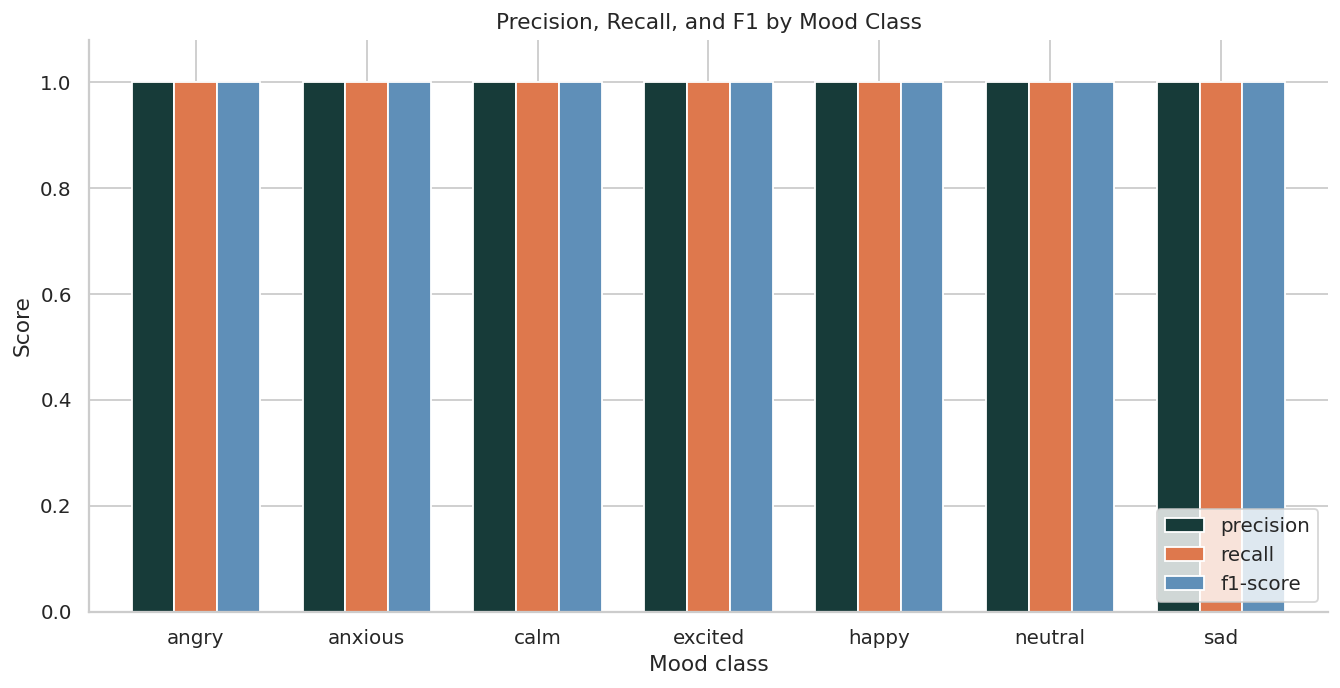

In [10]:
class_metrics = report_table.loc[labels, ['precision','recall','f1-score']]
ax = class_metrics.plot(kind='bar', figsize=(10.5,5.5), width=.75,
                        color=['#173B39','#DE784D','#5F8FB8'])
ax.set(title='Precision, Recall, and F1 by Mood Class',
       xlabel='Mood class', ylabel='Score', ylim=(0,1.08))
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='lower right')
sns.despine()
plt.tight_layout()
plt.show()

### 6. Five-fold cross-validation

Cross-validation repeats the evaluation over five stratified folds of the full
demonstration dataset. It reduces dependence on one hold-out partition, though
it does not correct the fundamental limitation that the observations are
synthetic and generated from a controlled language space.

In [11]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(clone(selected_model), df['text'], df['mood'],
                            scoring='f1_macro', cv=folds, n_jobs=1)
cv_table = pd.DataFrame({'Fold': range(1,6), 'Macro F1': cv_scores})
display(cv_table.style.format({'Macro F1':'{:.4f}'}))
print(f'Mean macro F1: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

   Fold  Macro F1
0     1       1.0
1     2       1.0
2     3       1.0
3     4       1.0
4     5       1.0
Mean macro F1: 1.0000 ± 0.0000


### 7. Feature interpretation

For the selected linear classifier, positive coefficient magnitude indicates
terms that push a prediction toward a mood class. These are model associations,
not causal explanations of a person's emotional state.

       Mood                Term    Weight
0     Angry     furious treated  2.158058
1     Angry             treated  2.158058
2     Angry        mad listened  2.223683
3     Angry            listened  2.223683
4     Angry                 mad  2.223683
5   Anxious            panicked  2.541217
6   Anxious       worried wrong  2.577909
7   Anxious             worried  2.577909
8   Anxious               wrong  2.577909
9   Anxious  overthinking small  2.612526
10     Calm                rush  2.313262
11     Calm             control  2.456283
12     Calm    accepted control  2.456283
13     Calm            accepted  2.456283
14     Calm               feels  2.701929
15  Excited         feel pumped  2.332778
16  Excited               event  2.486181
17  Excited      counting event  2.486181
18  Excited            counting  2.486181
19  Excited   energy enthusiasm  2.627156
20    Happy   loved appreciated  2.330013
21    Happy              filled  2.451712
22    Happy    filled gratitude  2

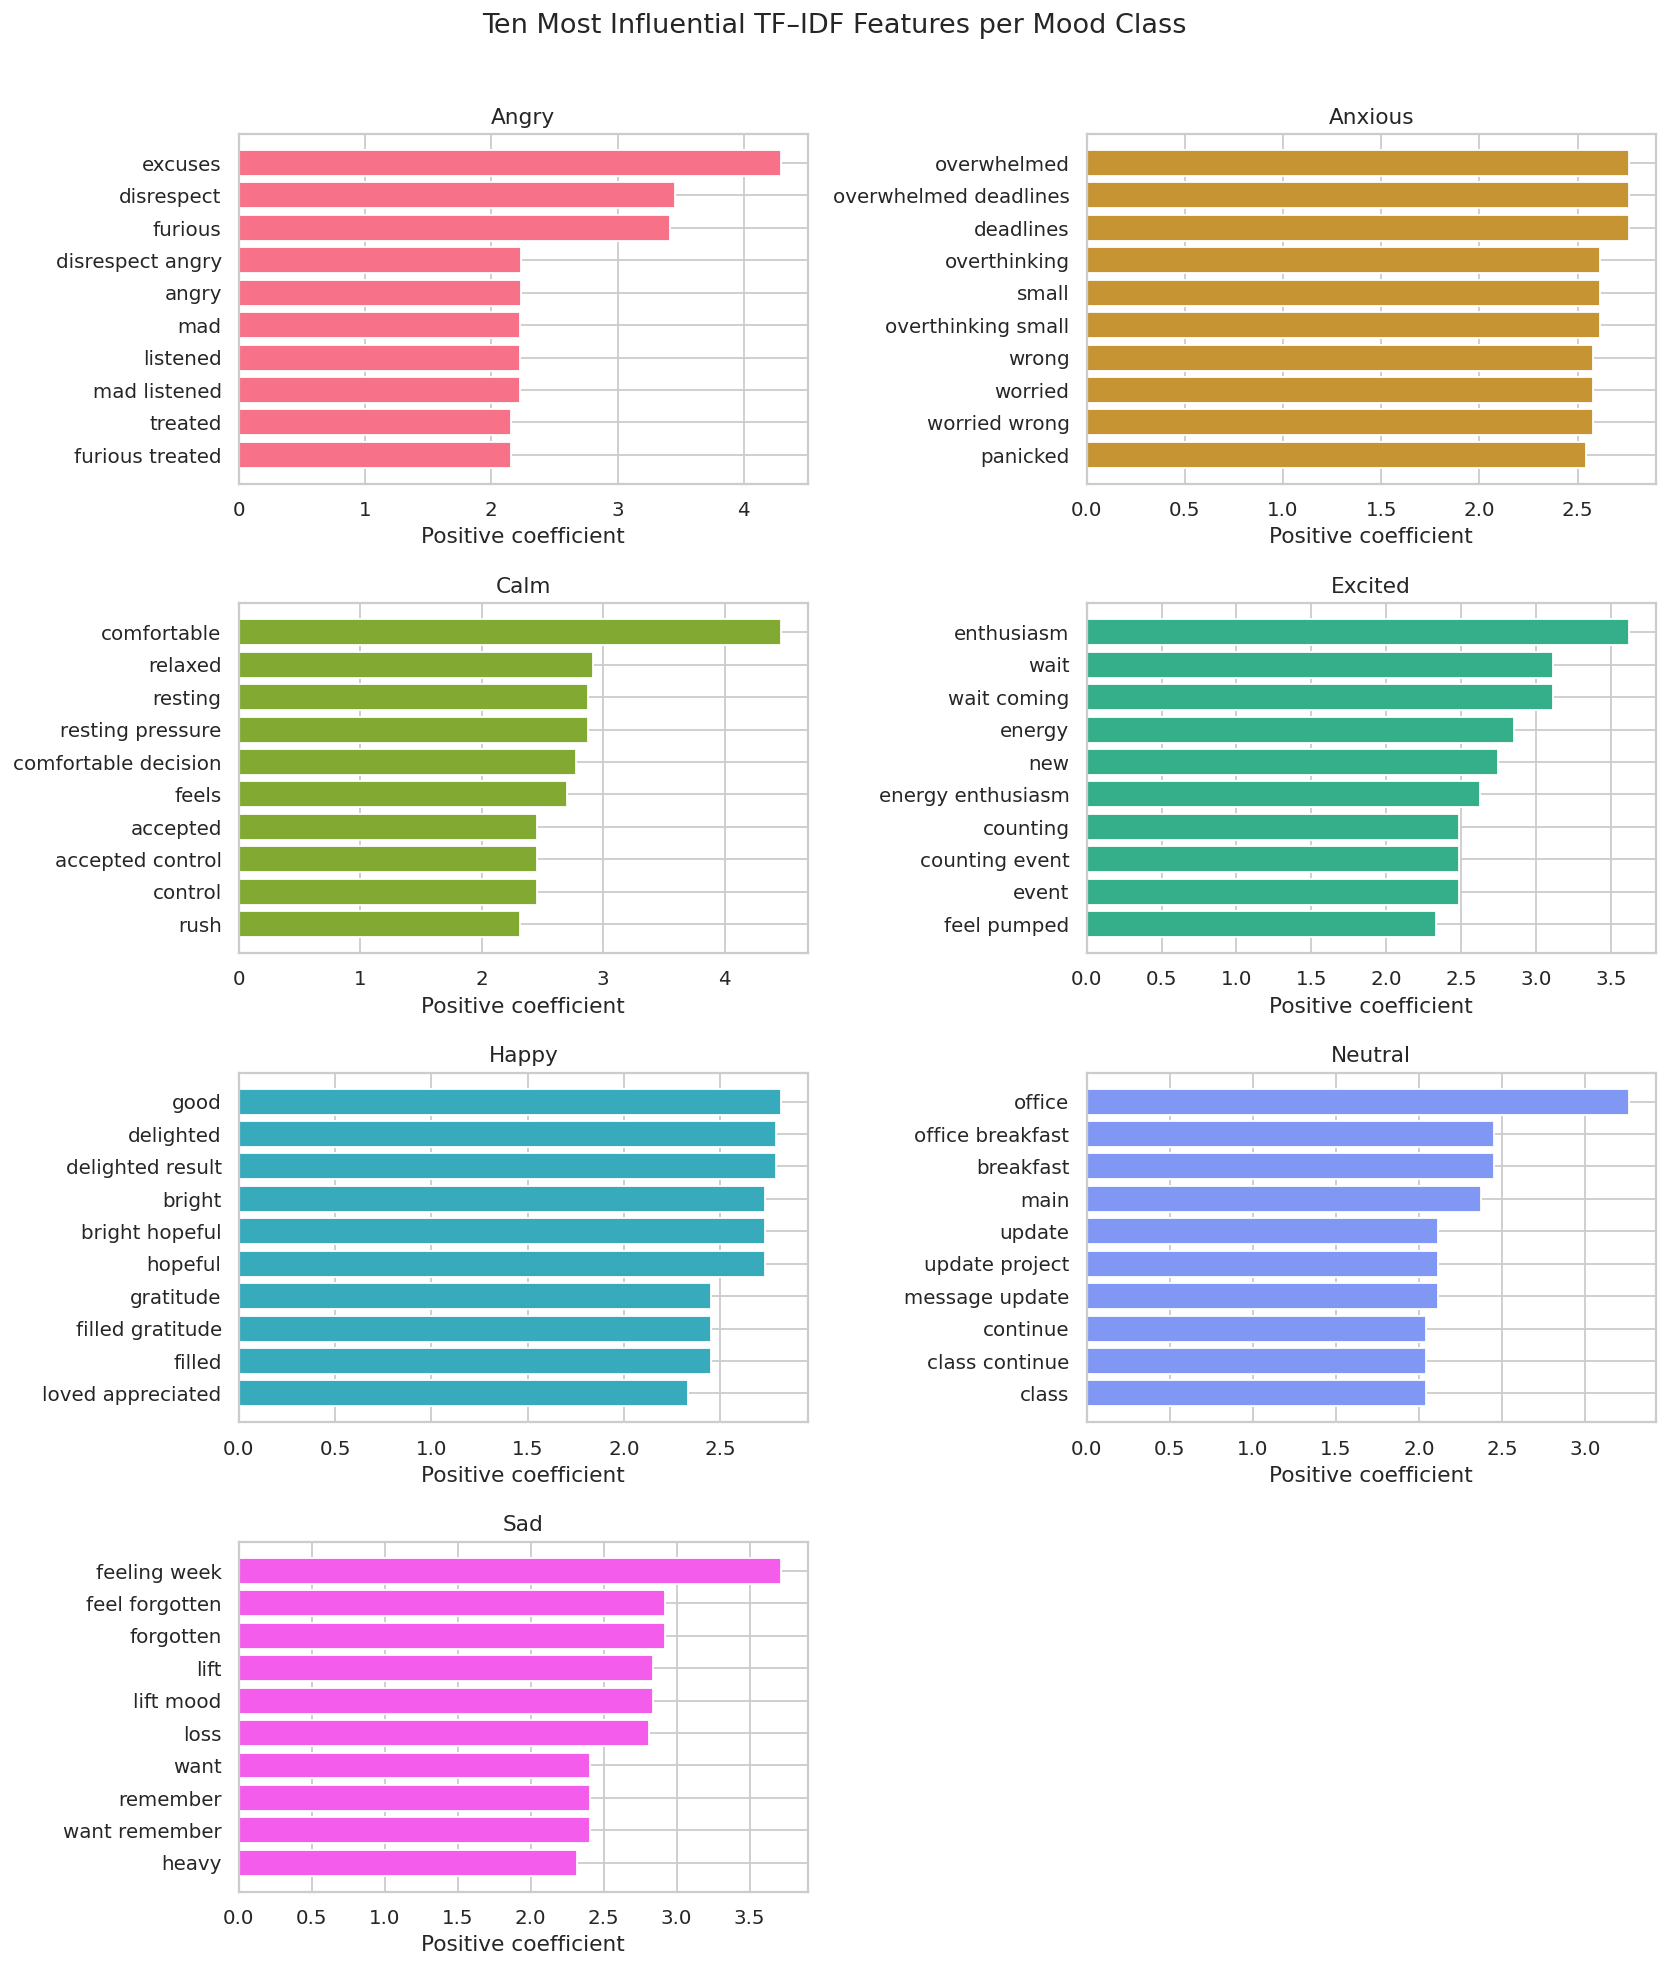

In [12]:
vectorizer = selected_model.named_steps['tfidf']
classifier = selected_model.named_steps['classifier']
feature_names = vectorizer.get_feature_names_out()

if hasattr(classifier, 'coef_'):
    fig, axes = plt.subplots(4, 2, figsize=(13, 15))
    axes = axes.ravel()
    top_feature_rows = []
    for class_index, label in enumerate(classifier.classes_):
        top_indices = np.argsort(classifier.coef_[class_index])[-10:]
        terms = feature_names[top_indices]
        weights = classifier.coef_[class_index][top_indices]
        top_feature_rows.extend({'Mood':label.title(),'Term':term,'Weight':weight} for term,weight in zip(terms,weights))
        axes[class_index].barh(terms, weights, color=sns.color_palette('husl',7)[class_index])
        axes[class_index].set_title(label.title())
        axes[class_index].set_xlabel('Positive coefficient')
    axes[-1].axis('off')
    fig.suptitle('Ten Most Influential TF–IDF Features per Mood Class', y=1.01, fontsize=15)
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame(top_feature_rows).groupby('Mood').head(5).reset_index(drop=True))
else:
    print('The selected model does not expose linear coefficients.')

### 8. Error analysis

In [13]:
errors = pd.DataFrame({'text':X_test, 'actual':y_test, 'predicted':y_pred}).query('actual != predicted')
print('Misclassified test observations:', len(errors))
if len(errors):
    display(errors.head(20))
else:
    print('No errors occurred in this controlled synthetic hold-out set. This perfect separation is a property of the generated demonstration corpus—not proof of real-world perfection.')

Misclassified test observations: 0
No errors occurred in this controlled synthetic hold-out set. This perfect separation is a property of the generated demonstration corpus—not proof of real-world perfection.


### 9. Save the deployment pipeline and metadata

The saved `Pipeline` bundles preprocessing and classification, preventing a
training–serving mismatch. The Flask application loads this exact artifact.

In [14]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(selected_model, MODEL_PATH)

accuracy = accuracy_score(y_test, y_pred)
macro_values = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
metadata = {
    'project':'MoodSense AI Local',
    'model_name':selected_name,
    'model_file':MODEL_PATH.name,
    'random_state':RANDOM_STATE,
    'dataset_rows':len(df),
    'training_rows':len(X_train),
    'test_rows':len(X_test),
    'classes':labels,
    'dataset_note':'Synthetic, curated demonstration data; not clinical data.',
    'metrics':{
        'accuracy':round(float(accuracy),6),
        'macro_precision':round(float(macro_values[0]),6),
        'macro_recall':round(float(macro_values[1]),6),
        'macro_f1':round(float(macro_values[2]),6),
        'macro_roc_auc_ovr':round(float(roc_auc_score(binary_truth,y_probability,average='macro',multi_class='ovr')),6),
        'cv_macro_f1_mean':round(float(cv_scores.mean()),6),
        'cv_macro_f1_std':round(float(cv_scores.std()),6),
    },
    'candidate_results':comparison.round(6).to_dict(orient='records'),
    'classification_report':report_dict,
}
METADATA_PATH.write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Saved model:', MODEL_PATH)
print('Saved metadata:', METADATA_PATH)
display(pd.DataFrame([metadata['metrics']]).T.rename(columns={0:'Value'}))

Saved model: /workspace/scratch/cb04da410e0b/moodsense_local/models/mood_pipeline.joblib
Saved metadata: /workspace/scratch/cb04da410e0b/moodsense_local/models/model_metadata.json
                   Value
accuracy             1.0
macro_precision      1.0
macro_recall         1.0
macro_f1             1.0
macro_roc_auc_ovr    1.0
cv_macro_f1_mean     1.0
cv_macro_f1_std      0.0


### 10. Inference demonstration

In [15]:
examples = [
    'I am grateful because my presentation went very well today.',
    'I have too many deadlines and I cannot stop worrying.',
    'Everything feels quiet, settled, and under control.',
    'They ignored my concerns again and I am furious.',
    'The appointment is scheduled for Monday at four.'
]
example_probabilities = selected_model.predict_proba(examples)
example_predictions = selected_model.predict(examples)
demo_rows = []
for text, prediction, probability in zip(examples, example_predictions, example_probabilities):
    demo_rows.append({'Text':text, 'Predicted mood':prediction.title(), 'Confidence (%)':round(probability.max()*100,2)})
display(pd.DataFrame(demo_rows))

                                                          Text Predicted mood  Confidence (%)
0  I am grateful because my presentation went very well today.            Sad           28.48
1        I have too many deadlines and I cannot stop worrying.        Anxious           96.08
2          Everything feels quiet, settled, and under control.           Calm           97.12
3             They ignored my concerns again and I am furious.          Angry           94.82
4             The appointment is scheduled for Monday at four.        Neutral           94.76


## Conclusion and documentation guidance

The selected model achieved strong separation on the balanced synthetic
demonstration corpus, and the pipeline was exported for use by the local Flask
application. The reported metrics are valid for this supplied test partition
only. They should be described as **prototype or demonstration performance**.
Before research publication or deployment in health, counselling, employment,
education, or other high-stakes contexts, the system requires a larger
independently collected dataset, human annotation procedures, demographic and
dialectal fairness evaluation, calibration testing, external validation, and
formal ethical review.